**WandB training curves without manual CSV download**

Run `wandb login` once before using this notebook.

In [81]:
from pathlib import Path
import os
import sys

FIGURES_DIR = Path.cwd()
if FIGURES_DIR.name != "figures" and (FIGURES_DIR / "figures").exists():
    FIGURES_DIR = FIGURES_DIR / "figures"
os.chdir(FIGURES_DIR)
sys.path.insert(0, str(FIGURES_DIR))

import importlib
import wandb_training_curves
importlib.reload(wandb_training_curves)

from wandb_training_curves import (
    DEFAULT_ENTITY,
    build_plot_config,
    fetch_wandb_training_curves,
    plot,
    print_performance_table,
    plot_final_distribution,
    plot_horizontal_legend
)

ENTITY = DEFAULT_ENTITY

**Stag Hunt**

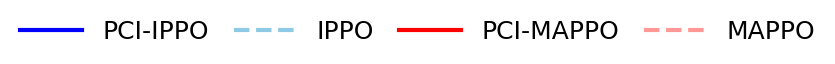

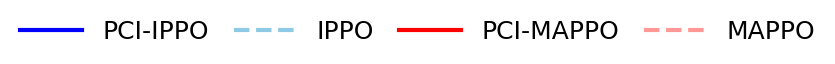

In [82]:
SH_DIR = Path("wandb_cache/SH")

sh_config = build_plot_config("sh", SH_DIR)

# Extract model legend
plot_horizontal_legend(
    sh_config,
    figsize=(5, 0.8),
)

In [83]:
import pandas as pd
import matplotlib.pyplot as plt

WINDOW = 20
LAST_N = 200
SH_SUBPLOT_FIGSIZE = (5, 4.5)
SH_FONT_SIZE = 20


def matching_success_rate_columns(df, entry):
    keyword = entry.get("keyword", "success_rate")
    exclude = entry.get("exclude", None)
    clean_kw = keyword.lower().replace("_", "").replace("-", "")
    cols = []
    for col in df.columns:
        col_lower = col.lower()
        if "success_rate" not in col_lower:
            continue
        clean_col = col_lower.replace("_", "").replace("-", "")
        if clean_kw not in clean_col:
            continue
        if "MIN" in col or "MAX" in col or "_step" in col:
            continue
        if exclude and exclude.lower() in col_lower:
            continue
        cols.append(col)
    return cols


def plot_sh_model_on_axis(ax, model_config, window_size=WINDOW, show_std_shading=True):
    try:
        df = pd.read_csv(model_config["path"])
    except FileNotFoundError:
        print(f"[WARN] File not found: {model_config['path']}")
        return

    cols = matching_success_rate_columns(df, model_config)
    if not cols:
        print(f"[WARN] No matching columns for {model_config['label']} in {model_config['path']}")
        return

    x = df["total_steps"]
    y_mean = df[cols].mean(axis=1).rolling(window=window_size, min_periods=1).mean()
    y_std = df[cols].std(axis=1).rolling(window=max(5, window_size // 4), min_periods=1).mean()

    ax.plot(
        x,
        y_mean,
        color=model_config["color"],
        linestyle=model_config.get("linestyle", "-"),
        linewidth=model_config.get("linewidth", 2),
    )
    if show_std_shading:
        ax.fill_between(
            x,
            y_mean - y_std,
            y_mean + y_std,
            color=model_config["color"],
            alpha=0.15,
            linewidth=0,
        )

    ax.set_xlabel("Total Steps", fontsize=SH_FONT_SIZE)
    ax.set_xlim(0, 3e6)
    ax.set_ylim(0, 1)
    ax.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
    ax.tick_params(axis="both", labelsize=SH_FONT_SIZE)
    ax.grid(True, linestyle="--", alpha=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def plot_sh_model_subplots(plot_config, show_std_shading=True):
    with plt.rc_context({
        "font.size": SH_FONT_SIZE,
        "axes.labelsize": SH_FONT_SIZE,
        "xtick.labelsize": SH_FONT_SIZE,
        "ytick.labelsize": SH_FONT_SIZE,
        "legend.fontsize": SH_FONT_SIZE,
    }):
        fig, axes = plt.subplots(
            1,
            len(plot_config),
            figsize=(SH_SUBPLOT_FIGSIZE[0] * len(plot_config), SH_SUBPLOT_FIGSIZE[1]),
            sharey=True,
        )
        if len(plot_config) == 1:
            axes = [axes]

        for ax, model_config in zip(axes, plot_config):
            plot_sh_model_on_axis(ax, model_config, show_std_shading=show_std_shading)

        axes[0].set_ylabel("Success Rate", fontsize=SH_FONT_SIZE)
        fig.tight_layout()
        display(fig)
        plt.close(fig)


# fetch_wandb_training_curves(
#     preset="sh",
#     entity=ENTITY,
#     output_dir=SH_DIR,
#     state="finished",
# )


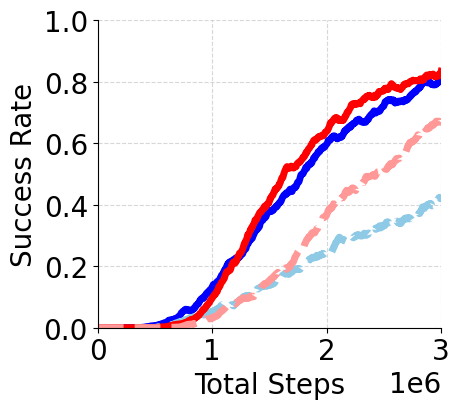

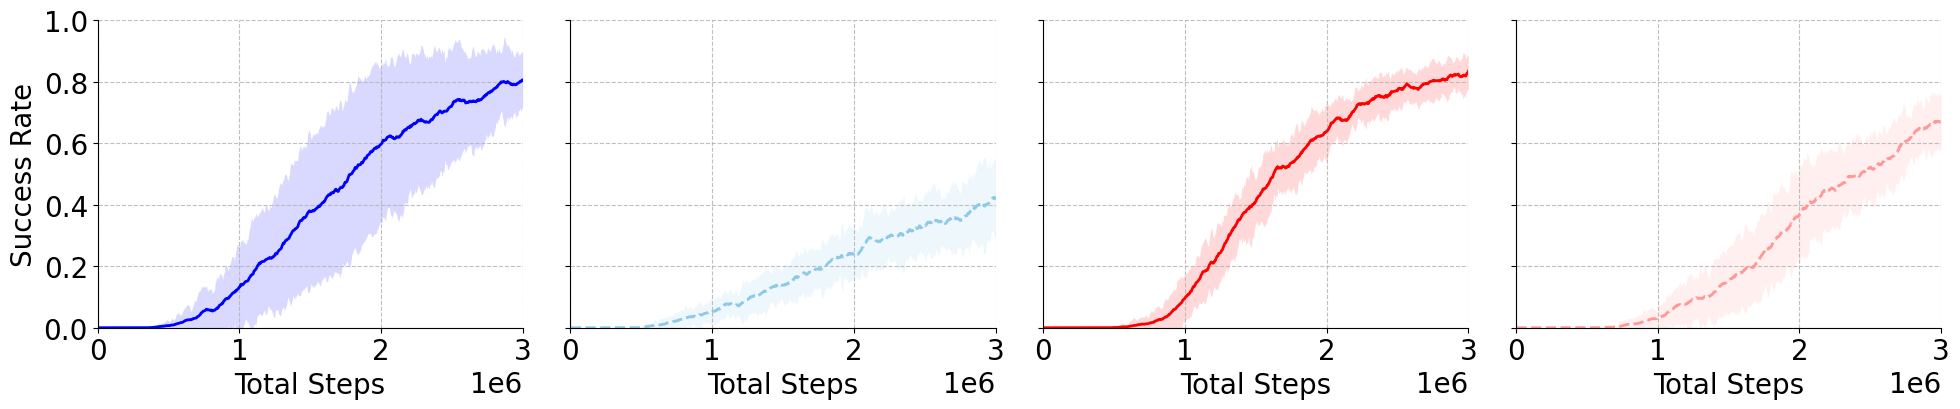

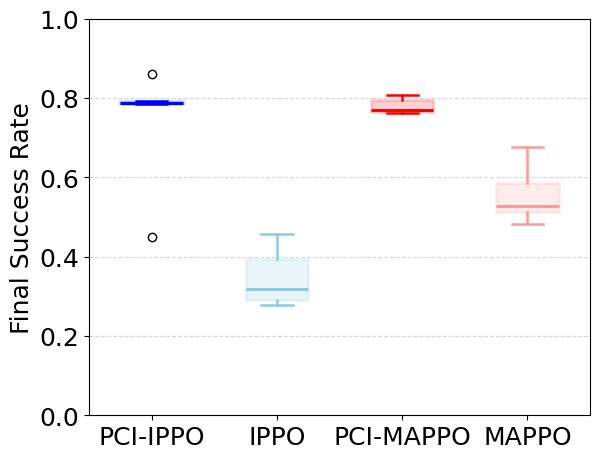


Final Performance Summary (Success Rate)
Based on last 200 points with window_size=20
Algorithm       N     Mean +/- Std    Min      Max     
--------------------------------------------------------------------------------
PCI-IPPO        5     0.734+/-0.146   0.449    0.861   
IPPO            5     0.347+/-0.069   0.277    0.458   
PCI-MAPPO       5     0.779+/-0.018   0.761    0.808   
MAPPO           5     0.556+/-0.069   0.481    0.677   
Note: Values are success rates (0-1 scale)


In [84]:
# Figure 2 plots
plot(sh_config, 
    window_size=WINDOW, 
    figsize=(5, 4.5), 
    xlim=(0, 3e6),
    ylim=(0, 1),
    mean_only=True,
    )

# Appendix Plots
plot_sh_model_subplots(sh_config, show_std_shading=True)

# 2) final performance distribution
plot_final_distribution(
    sh_config,
    window_size=WINDOW,
    last_n=LAST_N,
    figsize=(6.4, 5),
    ylim=(0, 1),
    show_seed_points=False,
    )

# 3) summary table
print_performance_table(
    sh_config,
    window_size=WINDOW,
    last_n=LAST_N,
)

**Stag Hunt delta_t^i during training**

In [85]:
import pandas as pd
import matplotlib.pyplot as plt

DELTA_CASES = {
    "stag": {
        "label": "Stag",
        "patterns": ("delta_stag_reward",),
        "linestyle": "-",
        "file_suffix": "stag",
        "normalizer": 5 / 3,
    },
    "hare": {
        "label": "Hare",
        "patterns": ("delta_forage",),
        "linestyle": "--",
        "file_suffix": "hare",
        "normalizer": 3 / 3,
    },
    "no_reward": {
        "label": "Null",
        "patterns": ("delta_no_reward",),
        "linestyle": ":",
        "file_suffix": "null",
        "normalizer": 1,
    },
}

DELTA_MODELS = {
    "ipci": {"keyword": "PCI_rippo", "title": "PCI-IPPO", "color": "#0050a4"},
    "mpci": {"keyword": "PCI_rmappo", "title": "PCI-MAPPO", "color": "#b00020"},
}

def find_delta_csv(base_dir, model, case):
    base_dir = Path(base_dir)
    spec = DELTA_CASES[case]
    model = str(model).lower()
    path = base_dir / f"{model}_{spec['file_suffix']}.csv"
    if path.exists():
        return path

    candidates = []
    for path in base_dir.glob("*.csv"):
        lower_name = path.name.lower()
        if model in lower_name and spec["file_suffix"] in lower_name:
            candidates.append(path)
    return sorted(candidates)[0] if candidates else None

def build_delta_plot_config(base_dir, model="ipci", model_keyword=None):
    model = str(model).lower()
    if model_keyword is None:
        model_keyword = DELTA_MODELS.get(model, {}).get("keyword", model)
    model_color = DELTA_MODELS.get(model, {}).get("color", "tab:blue")
    config = []
    for case, spec in DELTA_CASES.items():
        path = find_delta_csv(base_dir, model, case)
        if path is None:
            print(f"[WARN] No delta CSV found for model={model}, case={case} in {base_dir}")
            continue
        config.append({
            "path": str(path),
            "label": spec["label"],
            "keyword": model_keyword,
            "case": case,
            "patterns": spec["patterns"],
            "color": model_color,
            "linestyle": spec["linestyle"],
            "normalizer": spec["normalizer"],
        })
    return config

def _delta_series(entry, window_size):
    file_path = entry["path"]
    keyword = entry["keyword"]
    patterns = entry["patterns"]

    try:
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        print(f"[WARN] File not found: {file_path}")
        return None

    clean_kw = keyword.lower().replace("_", "").replace("-", "")
    cols = []
    for col in df.columns:
        col_lower = col.lower()
        clean_col = col_lower.replace("_", "").replace("-", "")
        if clean_kw not in clean_col:
            continue
        if not any(pattern in col_lower for pattern in patterns):
            continue
        if "MIN" in col or "MAX" in col or "_step" in col:
            continue
        cols.append(col)

    if not cols:
        print(f"[WARN] No matching columns for keyword={keyword} / label={entry['label']} in {file_path}")
        return None

    step_col = "total_steps" if "total_steps" in df.columns else "_step"
    x = df[step_col]
    y_mean = df[cols].mean(axis=1).rolling(window=window_size, min_periods=1).mean()
    y_std = df[cols].std(axis=1).rolling(window=window_size, min_periods=1).mean()
    return x, y_mean, y_std

def _draw_delta_lines(ax, plot_config, window_size):
    for entry in plot_config:
        series = _delta_series(entry, window_size)
        if series is None:
            continue
        x, y_mean, y_std = series
        normalizer = entry.get("normalizer", 1)
        y_mean = y_mean / normalizer
        y_std = y_std / normalizer
        color = entry["color"]
        linestyle = entry.get("linestyle", "-")
        ax.plot(x, y_mean, color=color, linestyle=linestyle, linewidth=5)
        ax.fill_between(x, y_mean - y_std, y_mean + y_std, color=color, alpha=0.12, linewidth=0)

def _add_x_break_marks(ax_left, ax_right):
    d = 0.012
    kwargs = dict(transform=ax_left.transAxes, color="black", clip_on=False, linewidth=1)
    ax_left.plot((1 - d, 1 + d), (-d, +d), **kwargs)
    ax_left.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

    kwargs.update(transform=ax_right.transAxes)
    ax_right.plot((-d, +d), (-d, +d), **kwargs)
    ax_right.plot((-d, +d), (1 - d, 1 + d), **kwargs)

def plot_delta_t(
    plot_config,
    window_size=20,
    figsize=(7, 5),
    xlim=(0, 3e6),
    ylim=None,
    title=None,
    x_break=None,
):
    plt.close("all")
    plt.rc("font", size=20)
    plt.rc("axes", labelsize=20)
    plt.rc("xtick", labelsize=20)
    plt.rc("ytick", labelsize=20)
    plt.rc("legend", fontsize=20)

    if x_break is None:
        fig, ax = plt.subplots(figsize=figsize)
        axes = [ax]
    else:
        if xlim is None:
            raise ValueError("xlim must be set when using x_break")
        fig, (ax_left, ax_right) = plt.subplots(
            1,
            2,
            figsize=figsize,
            sharey=True,
            gridspec_kw={"width_ratios": [1.15, 1], "wspace": 0.06},
        )
        axes = [ax_left, ax_right]

    for ax in axes:
        ax.axhline(y=5, color="gray", linestyle=":", alpha=0.5)
        ax.axhline(y=3, color="gray", linestyle=":", alpha=0.5)
        _draw_delta_lines(ax, plot_config, window_size)
        if ylim is not None:
            ax.set_ylim(ylim)
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    if x_break is None:
        if xlim is not None:
            ax.set_xlim(xlim)
        ax.set_xlabel("Total Steps")
        ax.set_ylabel("Credit-Aligned Reward")
        if title:
            ax.set_title(title)
        plt.tight_layout()
        plt.show()
        plt.close(fig)
        return fig, ax

    ax_left, ax_right = axes
    ax_left.set_xlim(xlim[0], x_break[0])
    ax_right.set_xlim(x_break[1], xlim[1])
    ax_left.spines["right"].set_visible(False)
    ax_right.spines["left"].set_visible(False)
    ax_right.spines["right"].set_visible(False)
    ax_right.tick_params(labelleft=False, left=False)
    fig.supxlabel("Total Steps", fontsize=20, y=0.02)
    ax_left.set_ylabel("Credit-Aligned Reward")
    if title:
        fig.suptitle(title, fontsize=20, y=0.98)
    _add_x_break_marks(ax_left, ax_right)
    fig.subplots_adjust(left=0.13, right=0.98, bottom=0.15, top=0.96, wspace=0.06)
    plt.show()
    plt.close(fig)
    return fig, (ax_left, ax_right)

def plot_delta_legend(figsize=(4.5, 0.7), color="black", ncol=3):
    from matplotlib.lines import Line2D

    plt.close("all")
    plt.rc("font", size=20)
    plt.rc("legend", fontsize=20)
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")
    handles = [
        Line2D([0], [0], color=color, linestyle=spec["linestyle"], linewidth=2, label=spec["label"])
        for spec in DELTA_CASES.values()
    ]
    ax.legend(
        handles=handles,
        labels=[handle.get_label() for handle in handles],
        loc="center",
        ncol=ncol,
        frameon=False,
        handlelength=2.8,
        columnspacing=1.4,
        fontsize=20,
    )
    plt.tight_layout(pad=0.1)
    plt.show()
    plt.close(fig)
    return fig, ax


/tmp/ipykernel_1654944/3815206969.py:221: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=0.1)


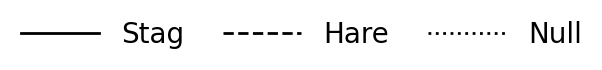

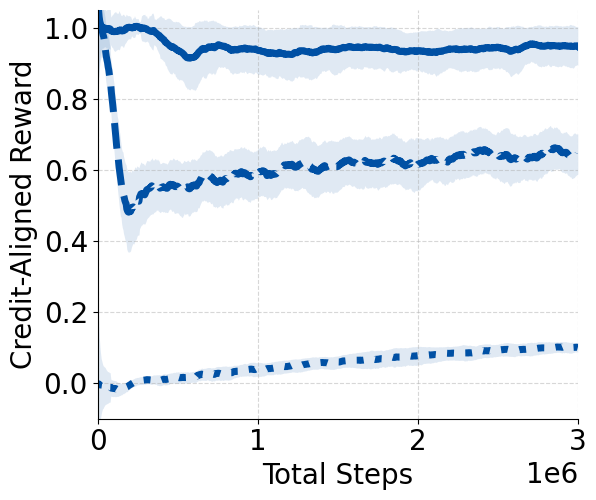

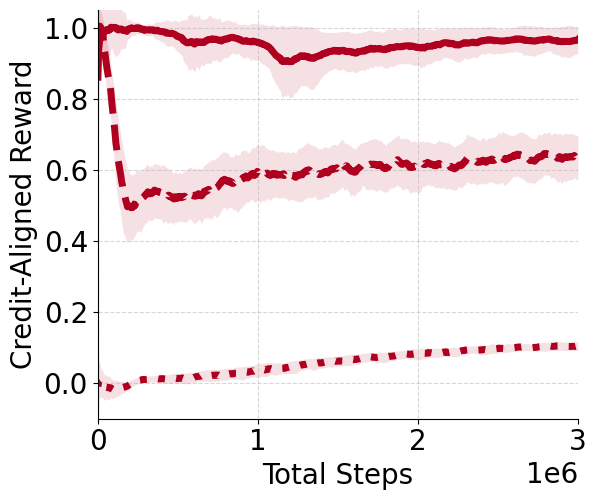

In [86]:
plot_delta_legend(figsize=(6.7, 0.1))

for model in ("ipci", "mpci"):
    sh_delta_config = build_delta_plot_config(SH_DIR, model=model)
    plot_delta_t(
        sh_delta_config,
        window_size=WINDOW,
        figsize=(6.5, 5.4),
        ylim=(-0.1, 1.05),
        xlim=(0, 3e6),
    )


**Stag Hunt with Observation Noise**

This cell collects only finished StagHunt runs whose run name ends with `_noise0.1`.

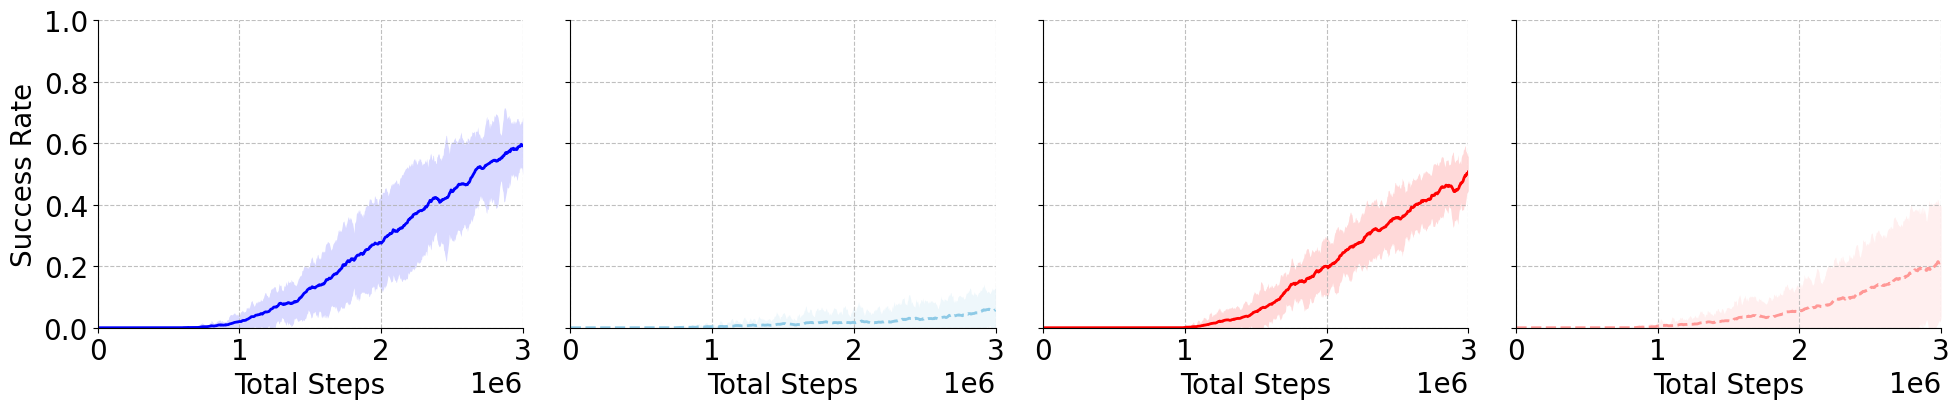

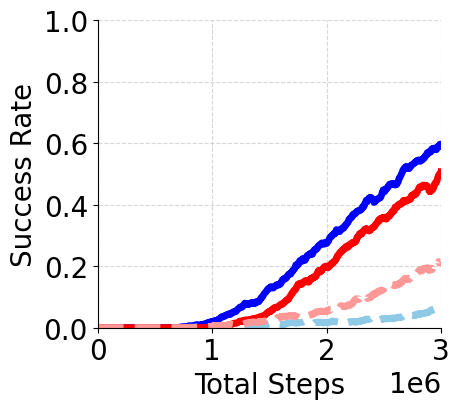

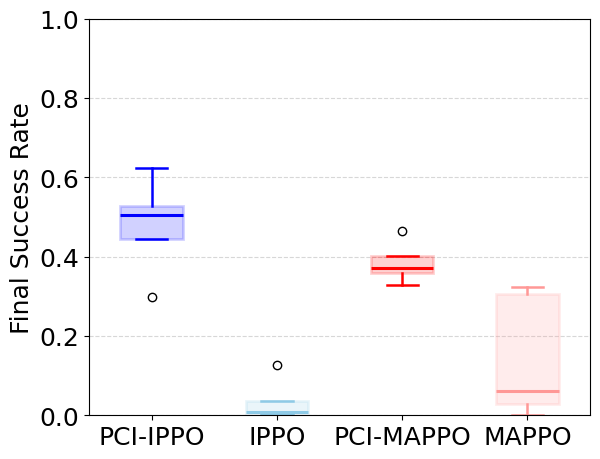


Final Performance Summary (Success Rate)
Based on last 200 points with window_size=20
Algorithm       N     Mean +/- Std    Min      Max     
--------------------------------------------------------------------------------
PCI-IPPO        5     0.479+/-0.108   0.297    0.623   
IPPO            5     0.036+/-0.047   0.002    0.128   
PCI-MAPPO       5     0.385+/-0.046   0.329    0.465   
MAPPO           5     0.143+/-0.141   0.000    0.322   
Note: Values are success rates (0-1 scale)


In [87]:
SH_NOISE_DIR = Path("wandb_cache/SH_noise0.1")

# fetch_wandb_training_curves(
#     preset="sh-noise",
#     entity=ENTITY,
#     output_dir=SH_NOISE_DIR,
#     state="finished",
# )

sh_noise_config = build_plot_config("sh-noise", SH_NOISE_DIR)

plot_sh_model_subplots(sh_noise_config, show_std_shading=True)
plot(sh_noise_config, 
    window_size=WINDOW, 
    figsize=(5, 4.5), 
    xlim=(0, 3e6),
    ylim=(0, 1),
    mean_only=True,
    )

# 2) final performance distribution
plot_final_distribution(
    sh_noise_config,
    window_size=WINDOW,
    last_n=LAST_N,
    figsize=(6.4, 5),
    ylim=(0, 1),
    show_seed_points=False,
)

# 3) summary table
print_performance_table(
    sh_noise_config,
    window_size=WINDOW,
    last_n=LAST_N,
)


**Stag Hunt with Observation Noise delta_t^i during training**

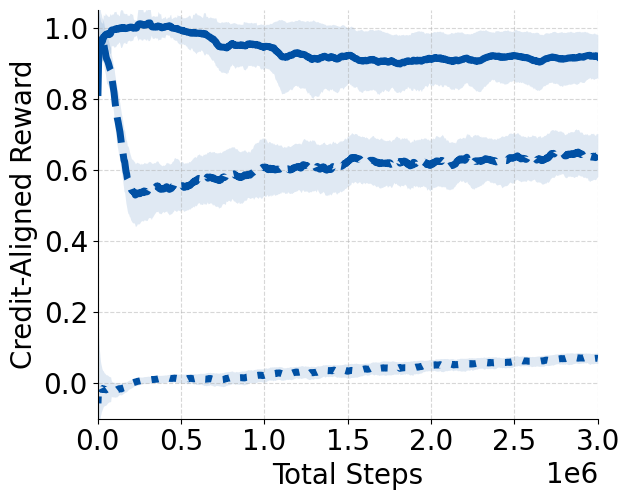

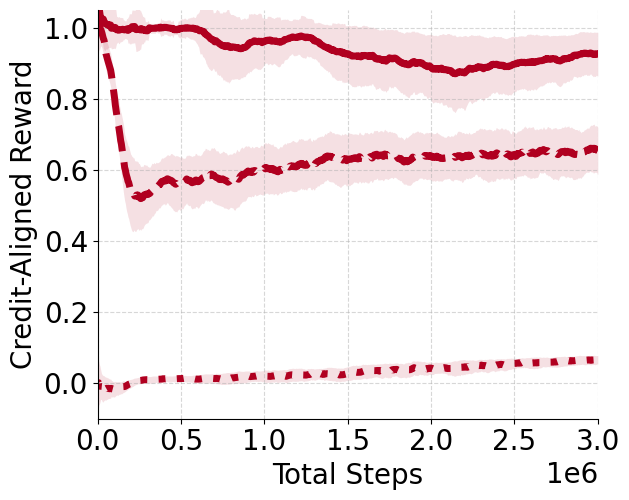

In [88]:
for model in ("ipci", "mpci"):
    sh_noise_delta_config = build_delta_plot_config(SH_NOISE_DIR, model=model)
    plot_delta_t(
        sh_noise_delta_config,
        window_size=WINDOW,
        figsize=(6.7, 5.4),
        ylim=(-0.1, 1.05),
        xlim=(0, 3e6),
    )


**CLI examples**

In [89]:
# !python wandb_training_curves.py --preset sh --plot --save-png sh_training_curve.png
# !python wandb_training_curves.py --preset sh-noise --plot --save-png sh_noise0.1_training_curve.png
# !python wandb_training_curves.py --preset sh --name-suffix _noise0.1 --plot --save-png sh_noise0.1_training_curve.png
# !python wandb_training_curves.py --preset smax --list-runs --contains 2s3z
# !python wandb_training_curves.py --preset smax --contains 2s3z tar_w=4 --plot --save-png smax_2s3z_tarw4.png